In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Cleaning

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

FOLDER = '/content/drive/MyDrive/Masters/MSIN0143 Programming for Business Analytics Group Coursework/data/'
DATA_PATH = FOLDER + 'dft-road-casualty-statistics-collision-2025.csv'
DICT_PATH = FOLDER + 'dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
df = raw.copy()

dictionary = pd.read_excel(DICT_PATH, sheet_name='2024_code_list')
dictionary = dictionary[dictionary['table'] == 'collision']

In [ ]:
df.dtypes

,0
collision_index,object
collision_year,int64
collision_ref_no,object
location_easting_osgr,float64
location_northing_osgr,float64
longitude,float64
latitude,float64
police_force,int64
collision_severity,int64
number_of_vehicles,int64


In [ ]:
analysis_cols = [
    'collision_ref_no', 'collision_severity', 'number_of_vehicles', 'number_of_casualties',
    'date', 'day_of_week', 'time', 'local_authority_ons_district', 'first_road_class', 'road_type',
    'speed_limit', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing',
    'light_conditions', 'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards', 'urban_or_rural_area'
]

# Keep columns only used for this analysis
df = df[analysis_cols].copy()
print(f"Oringial: {raw.shape}, Analysis: {df.shape}")

Oringial: (101525, 44), Analysis: (101525, 21)


In [ ]:
df.head()

,collision_ref_no,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_ons_district,first_road_class,road_type,...,junction_detail,junction_control,second_road_class,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area
0,17M101925,3,1,1,04/02/2025,3,15:00,E06000002,4.0,6.0,...,0.0,NaN,0.0,13.0,1.0,1.0,1.0,NaN,0.0,1.0
1,17L205225,3,2,1,07/05/2025,4,09:35,E06000003,5.0,6.0,...,0.0,NaN,0.0,0.0,1.0,1.0,1.0,NaN,0.0,1.0
2,070971700,3,2,2,27/11/2025,5,18:18,E06000006,6.0,6.0,...,13.0,2.0,6.0,15.0,4.0,1.0,2.0,NaN,0.0,2.0
3,070403274,3,2,1,15/05/2025,5,16:30,E06000007,5.0,6.0,...,0.0,NaN,0.0,0.0,1.0,1.0,1.0,NaN,0.0,2.0
4,071000604,3,7,1,08/12/2025,2,07:45,E06000007,1.0,3.0,...,0.0,NaN,0.0,NaN,4.0,1.0,2.0,NaN,0.0,2.0


In [ ]:
# Check for duplicate wos and collision references
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df['collision_ref_no'].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


In [ ]:
# Replacing "unknown" values with missing values NaN
unknown_value = {
    'road_type': [9],
    'speed_limit': [99],
    'junction_detail': [99],
    'junction_control': [9],
    'second_road_class': [9],
    'pedestrian_crossing': [99],
    'weather_conditions': [9],
    'road_surface_conditions': [9],
    'special_conditions_at_site': [9],
    'carriageway_hazards': [99],
    'urban_or_rural_area': [3]
}

df = df.replace(-1, np.nan)
df = df.replace(unknown_value, np.nan)

# % missing per column after recoding
df.isna().mean().mul(100).round(1).sort_values()

,0
collision_ref_no,0.0
collision_severity,0.0
number_of_vehicles,0.0
number_of_casualties,0.0
date,0.0
day_of_week,0.0
time,0.0
local_authority_ons_district,0.0
first_road_class,0.0
speed_limit,0.0


In [ ]:
severity = df['collision_severity'].map({1: 'Fatal', 2: 'Serious', 3: 'Slight'})

severity_summary = pd.DataFrame({
    'count': severity.value_counts().sort_index(),
    'percent': severity.value_counts(normalize=True).mul(100).round(1)
}).reindex(['Fatal', 'Serious', 'Slight'])

severity_summary

,count,percent
collision_severity,,
Fatal,1453,1.4
Serious,25191,24.8
Slight,74881,73.8


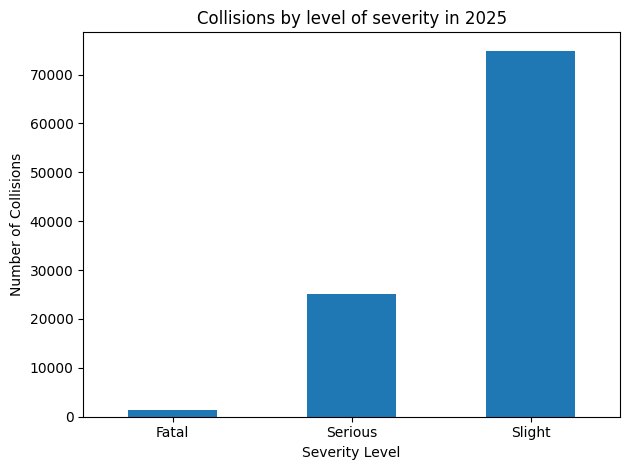

In [ ]:
ax = severity_summary['count'].plot(kind='bar')
ax.set_title('Collisions by level of severity in 2025')
ax.set_xlabel('Severity Level')
ax.set_ylabel('Number of Collisions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()